# Morocco Market Stress Index

A daily gauge of stress on the Casablanca Stock Exchange that combines **what the financial press says** with **what the market does**.

This notebook tells the story in six steps: problem, data, method, results, validation, limits. All helper code lives in `src/stress_index/`; every number below is computed here from the published data in `data/processed/`.

## 1. The problem

Investors in Moroccan equities have no widely used daily stress gauge comparable to the VIX for US stocks. Market signals such as volatility react to a shock only once prices have moved, while the news flow often turns first.

**Goal:** a single daily number between 0 and 100 that rises when several sources of stress (equities, bonds, oil, market breadth, press tone) flare up *at the same time*, built only from information available on each day, so it can feed allocation or risk decisions.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from stress_index import load_stress_index
from stress_index.config import load_config
from stress_index.pipeline import step_composite, step_sentiment
from stress_index.report import key_numbers, load_all, make_figures

pd.set_option("display.precision", 3)
cfg = load_config()

## 2. The data

* **Financial news.** Articles from two Moroccan financial news websites (labelled A and B), each scored for tone by a language model. Only the per-article scores are published, not the text.
* **Market data.** Daily closes of the MASI equity index, the MBI bond index and the listed stocks of the Casablanca Stock Exchange, plus Brent crude oil prices. Raw prices are not redistributed; the repository ships the derived components.

In [2]:
data = load_all(cfg)
scores = data["scores"]
per_year = scores.groupby([scores["date"].dt.year, "source"]).size().unstack(fill_value=0)
per_year.index.name = "year"
print(f"{len(scores):,} scored articles, {scores['date'].min():%Y-%m-%d} to {scores['date'].max():%Y-%m-%d}")
print(f"{data['market_meta']['n_stocks']} stocks, {data['market_meta']['n_trading_days']:,} trading days "
      f"({data['market_meta']['first_trading_day']} to {data['market_meta']['last_trading_day']})")
per_year

24,594 scored articles, 2018-01-02 to 2026-07-20
78 stocks, 2,097 trading days (2018-01-02 to 2026-07-17)


source,A,B
year,,
2018,976,1687
2019,904,2684
2020,999,3301
2021,765,2408
2022,519,1988
2023,331,2371
2024,291,1627
2025,436,1817
2026,249,1241


## 3. The method

1. **Score each article.** A French sentiment model (`cmarkea/distilcamembert-base-sentiment`) reads the title and the start of the text and returns a tone between −1 (reassuring) and +1 (alarming).
2. **Daily press sentiment.** Weighted average of the articles of the last 90 days, where an article's weight halves every 14 days.
3. **Six components**, all oriented so that *high = stress*: equity momentum, equity volatility, bond volatility, market breadth, news sentiment and oil volatility.
4. **Common scale.** Each component is replaced by its percentile rank against its own past year (0 = calmest day of the year, 1 = most stressed).
5. **Composite.** The ranks are combined with the CISS formula of the European Central Bank (Hollo, Kremer & Lo Duca, 2012), $\text{CISS}_t = (w \circ s_t)\,C_t\,(w \circ s_t)'$, where $C_t$ is the time-varying correlation between components. When components are stressed **together**, the index rises much more than when one channel alone is stressed. The index is $100 \times \text{CISS}$, so it is bounded between 0 and 100 by construction and past values are never revised.

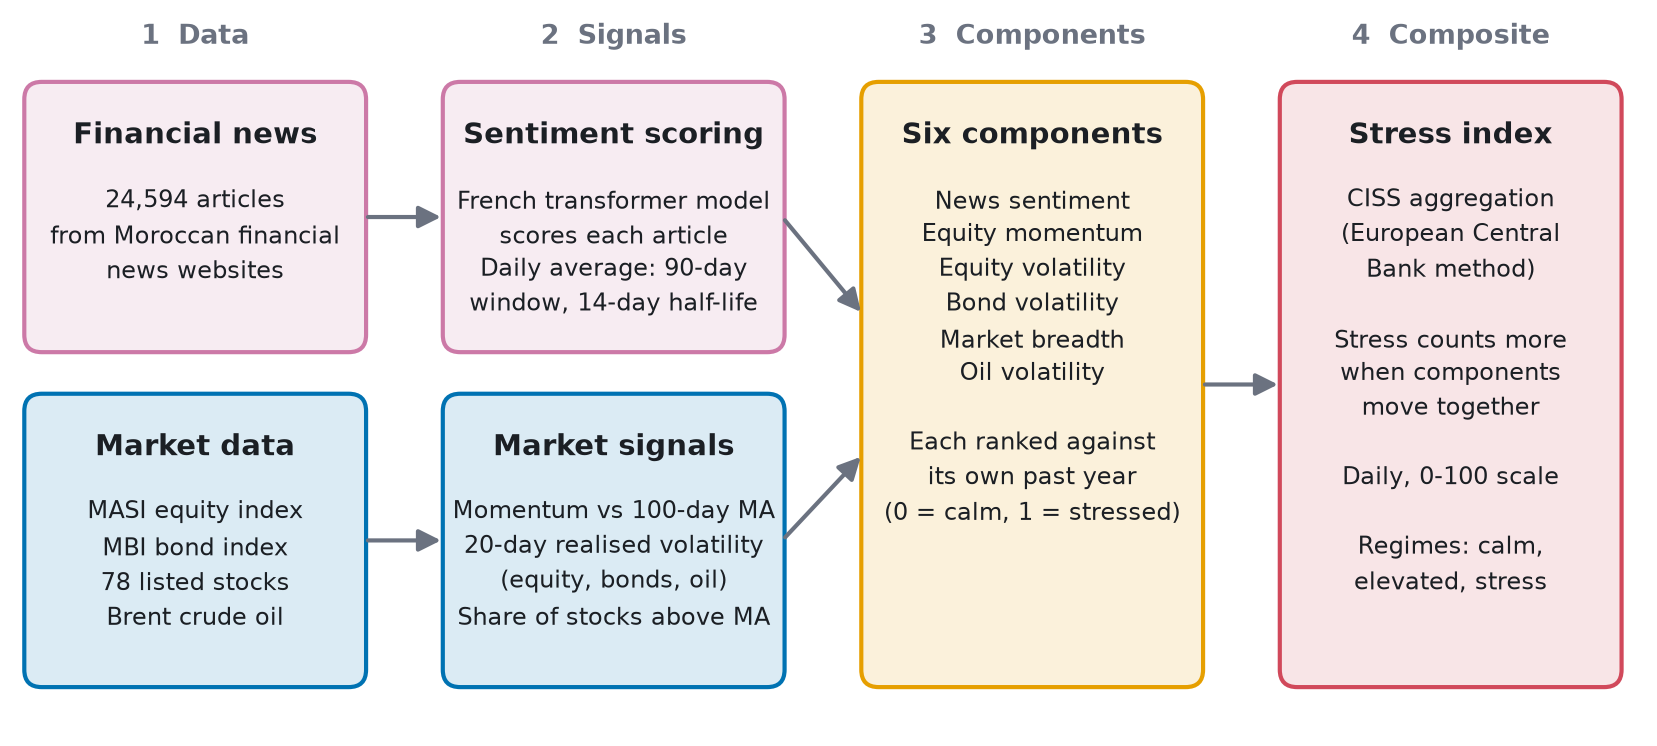

In [3]:
display(Image(ROOT / "figures" / "method_diagram.png", width=900))

The next cell rebuilds the sentiment series and the composite index from the published inputs, so everything that follows is reproducible from this repository alone.

In [4]:
sentiment = step_sentiment(cfg)
index = step_composite(cfg)
k = key_numbers(cfg, load_all(cfg))

sentiment index: 2758 days, 2019-01-01 -> 2026-07-20


stress index: 1608 days, 2019-11-25 -> 2026-07-17


## 4. Results

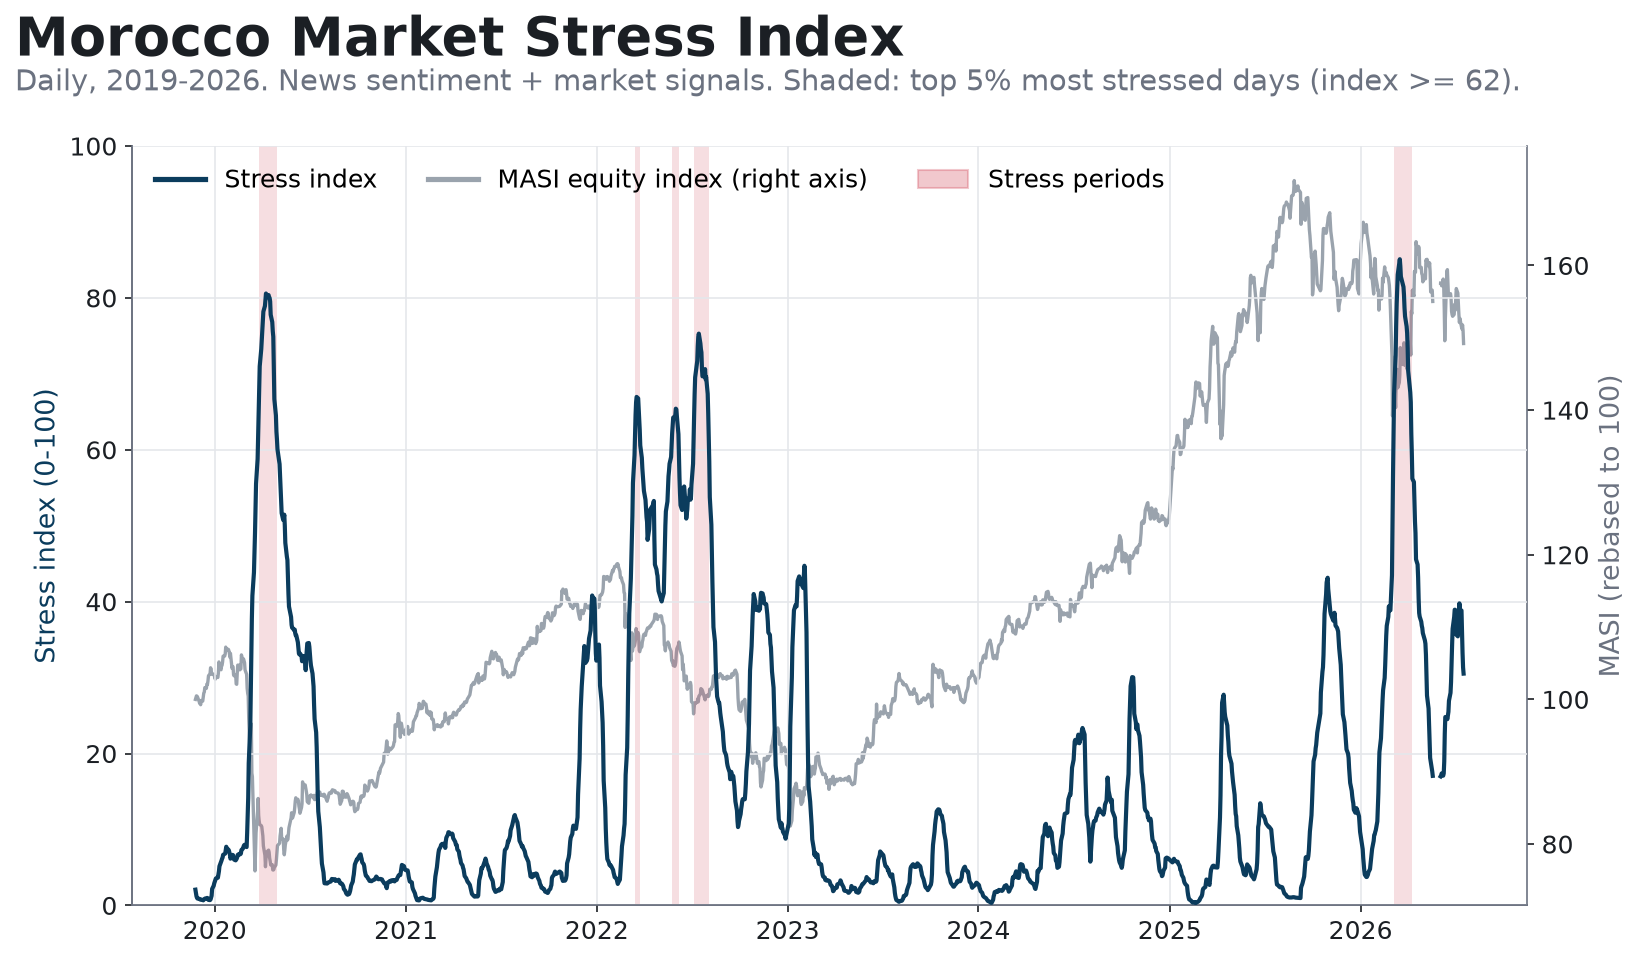

In [5]:
make_figures(cfg, load_all(cfg), k)
display(Image(ROOT / "figures" / "thumbnail.png", width=900))

In [6]:
ix = k["index"]
print(f"Index from {ix['first']} to {ix['last']} ({ix['n_days']:,} trading days)")
print(f"Median {ix['median']}, mean {ix['mean']}; highest {ix['max']} on {ix['max_date']}")
print(f"Latest value: {ix['last_value']} ({ix['last']}), real-time regime: {ix['last_regime']}")
pd.DataFrame(ix["peak_by_year"]).T.rename_axis("year")

Index from 2019-11-25 to 2026-07-17 (1,608 trading days)
Median 7.6, mean 17.2; highest 85.1 on 2026-03-17
Latest value: 30.5 (2026-07-17), real-time regime: elevated


,date,value
year,,
2019,2019-12-31,2.9
2020,2020-04-08,80.6
2021,2021-12-23,40.8
2022,2022-07-15,75.3
2023,2023-02-02,44.7
2024,2024-10-21,30.1
2025,2025-10-30,43.1
2026,2026-03-17,85.1


**What drives the index.** Contributions add up exactly to the index, so the chart below shows which channel pushed it up in each episode.

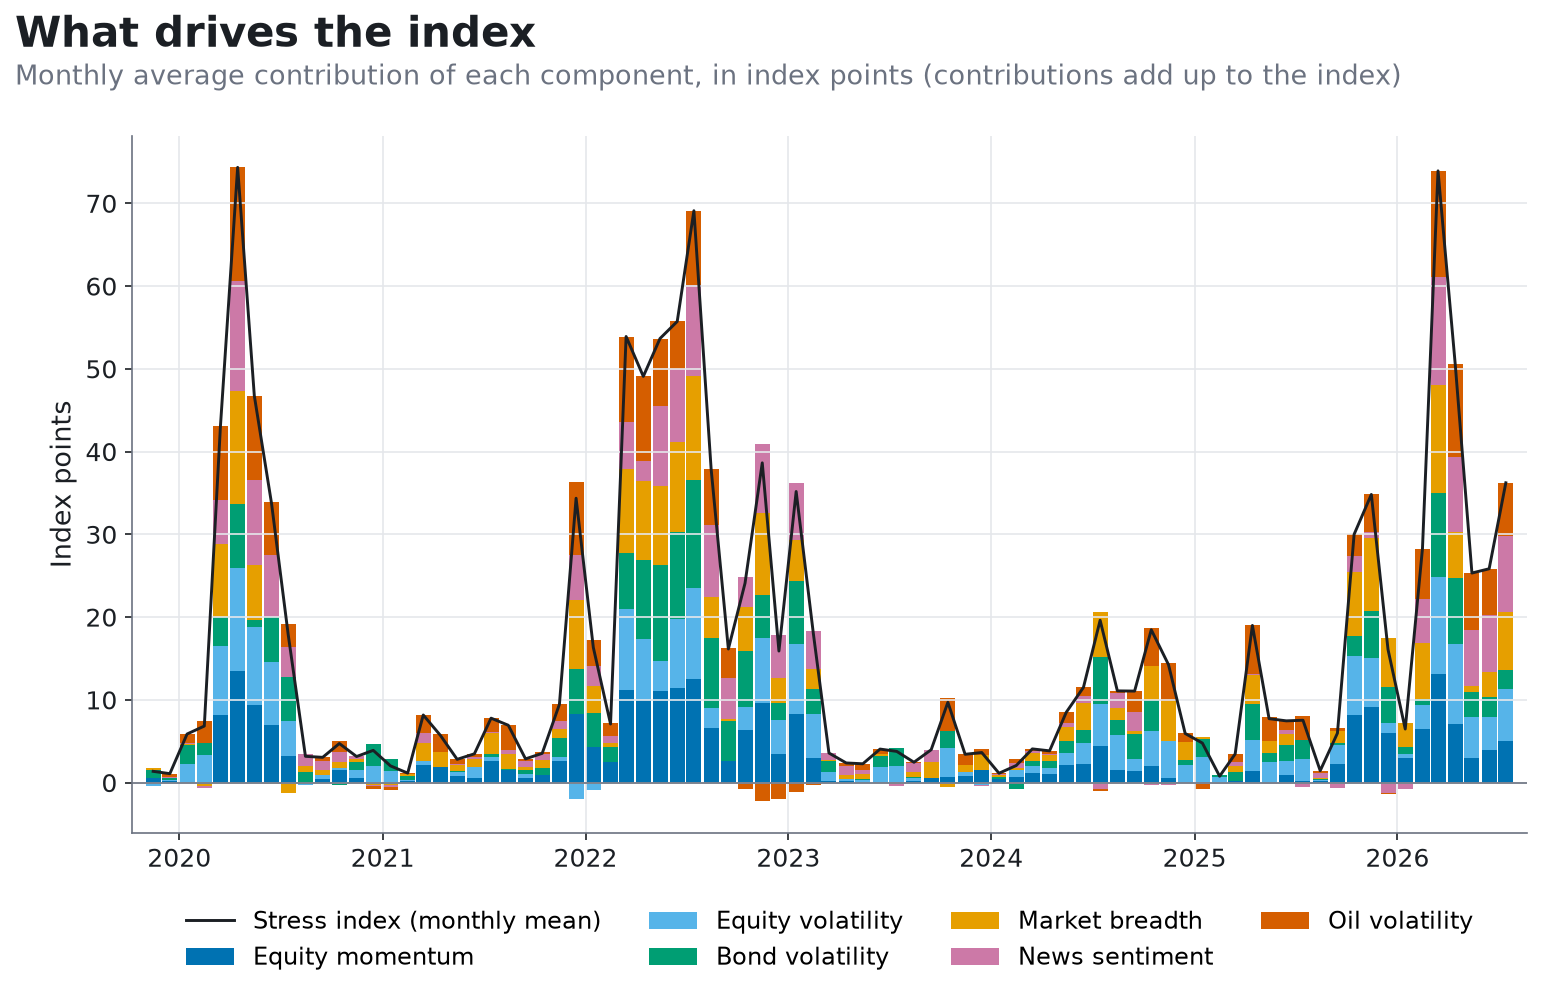

,average share of the index
equity_momentum,0.192
equity_volatility,0.170
bond_volatility,0.161
market_breadth,0.176
news_sentiment,0.144
oil_volatility,0.157


In [7]:
display(Image(ROOT / "figures" / "components.png", width=900))
pd.Series(k["index"]["mean_contribution_share"], name="average share of the index").to_frame()

**Real-time regimes.** A day is *elevated* above the 75th percentile and *stress* above the 95th percentile of the index **up to that day**. These labels need one year of index history before they exist.

In [8]:
pd.Series(k["index"]["realtime_regime_days"], name="days").to_frame()

,days
calm,1008
elevated,296
stress,53


## 5. Validation: does it measure stress?

Three checks, using MASI outcomes that the index could not see:

1. **Contemporaneous:** correlation with realised volatility and with the MASI drawdown.
2. **Forward-looking:** MASI volatility and worst fall over the *next* 20 trading days, by index quintile.
3. **Episodes:** behaviour of the index in every MASI fall of more than 10% in the sample. An episode is named after a news topic only when that topic's headline count was at least three times its usual rate.

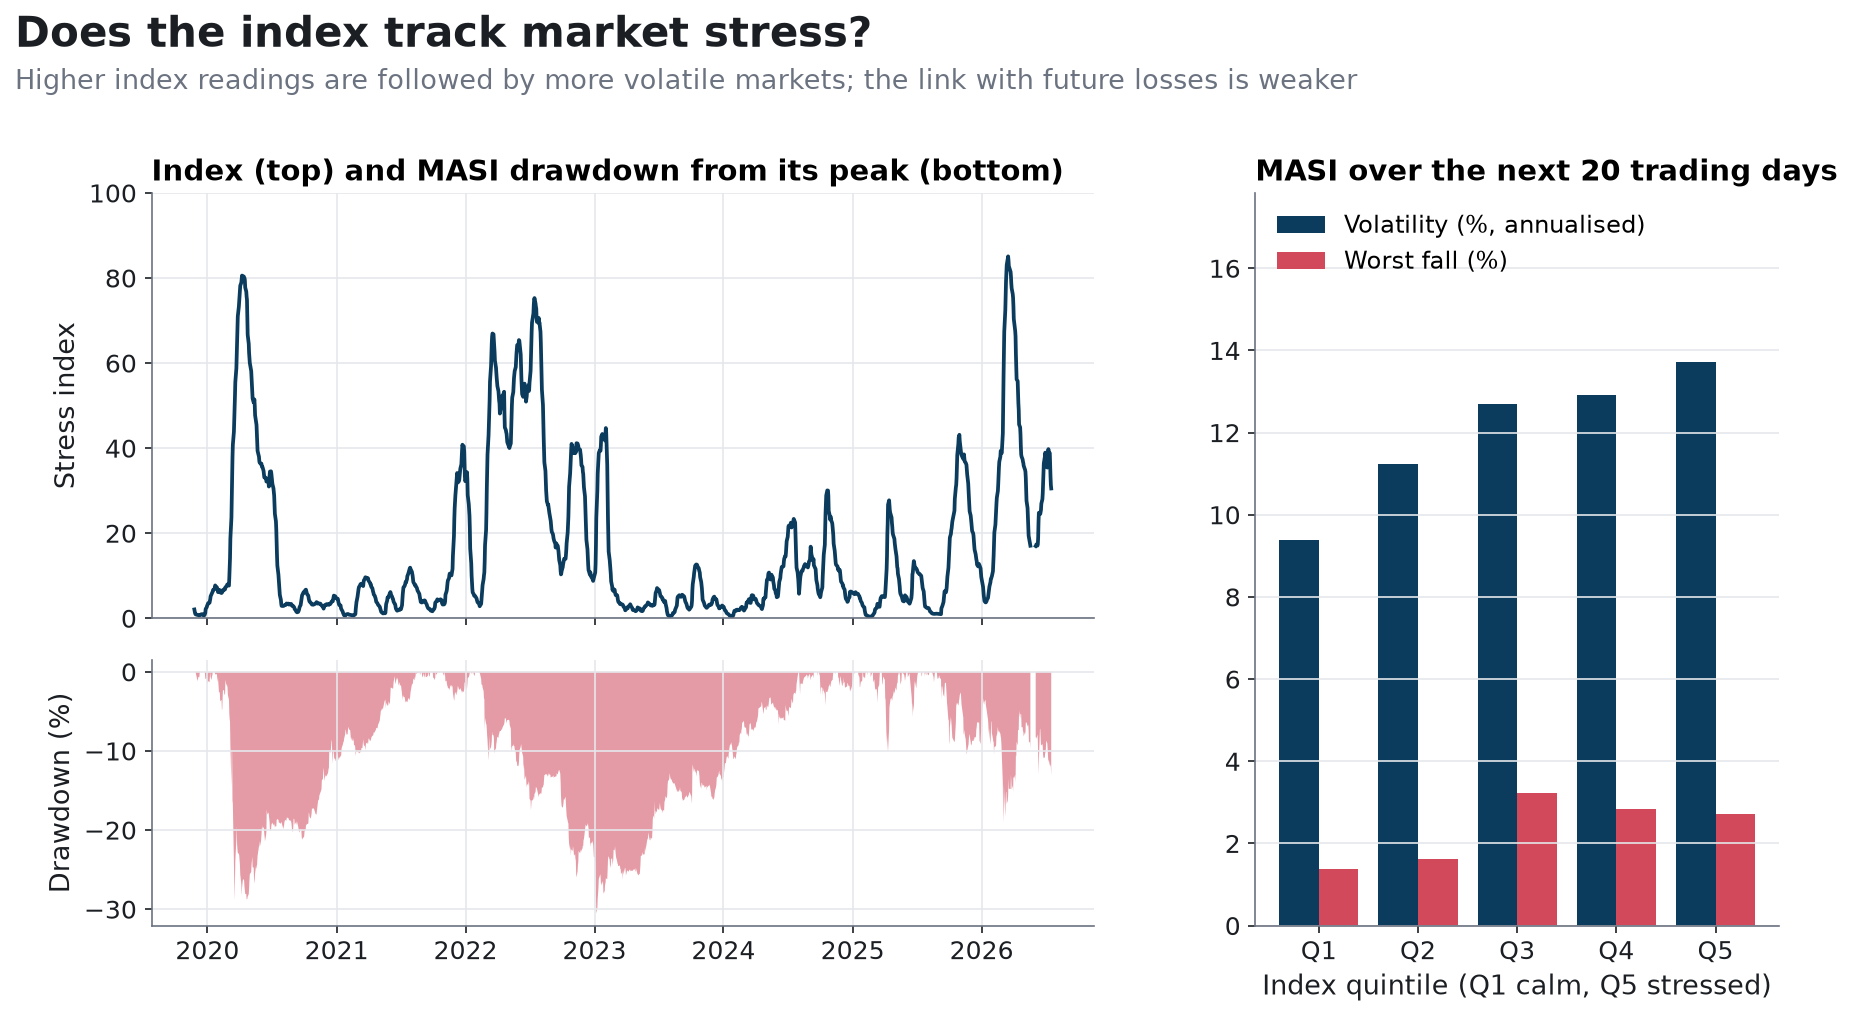

,n_days,pearson,spearman
drawdown,1608.0,-0.258,-0.116
realised_vol,1608.0,0.571,0.485
fwd_realised_vol,1588.0,0.134,0.227
fwd_max_drawdown,1588.0,-0.062,-0.115
fwd_return,1588.0,0.031,-0.059


In [9]:
display(Image(ROOT / "figures" / "validation.png", width=900))
pd.DataFrame(k["validation"]["correlations"]).T

In [10]:
pd.DataFrame(k["validation"]["quintiles"]).T

,n_days,index_mean,fwd_realised_vol_pct,fwd_max_drawdown_pct,realised_vol_pct
Q1,318.0,1.8,9.4,-1.37,7.8
Q2,317.0,4.0,11.2,-1.61,9.2
Q3,318.0,7.7,12.7,-3.23,10.1
Q4,317.0,19.8,12.9,-2.85,13.1
Q5,318.0,51.3,13.7,-2.71,18.8


In [11]:
ep = pd.DataFrame(k["validation"]["episodes"])
for c in ["peak", "trough", "index_max_date", "index_max_after_trough_date"]:
    ep[c] = pd.to_datetime(ep[c]).dt.date
ep[["peak", "trough", "masi_depth_pct", "index_before_mean", "index_max", "index_max_after_trough",
    "index_max_after_trough_date", "topic", "topic_headlines", "topic_excess_ratio"]]

,peak,trough,masi_depth_pct,index_before_mean,index_max,index_max_after_trough,index_max_after_trough_date,topic,topic_headlines,topic_excess_ratio
0,2020-01-22,2020-03-18,-28.9,2.7,49.0,80.6,2020-04-08,COVID-19,120,6.1
1,2022-02-10,2023-01-06,-30.5,21.1,75.3,44.7,2023-02-02,war in Ukraine,70,6.9
2,2025-03-24,2025-04-09,-10.3,3.2,19.7,27.7,2025-04-14,US tariffs,11,30.0
3,2025-08-27,2026-03-03,-19.0,5.7,50.7,85.1,2026-03-17,NaN,0,NaN


**Does it add information beyond current volatility?** Volatility is persistent, so part of the forward link is simply today's volatility. The table below removes it (partial rank correlation with next-20-day volatility, controlling for current volatility).

In [12]:
v = k["validation"]
pd.DataFrame({"partial corr. with next-20-day volatility": v["partial_spearman_fwd_vol_given_trailing_vol"],
              "partial corr. with next-20-day worst fall": v["partial_spearman_fwd_max_drawdown_given_trailing_vol"]})

,partial corr. with next-20-day volatility,partial corr. with next-20-day worst fall
stress_index,0.056,-0.056
equity_momentum,0.100,-0.040
equity_volatility,-0.083,0.052
bond_volatility,0.032,-0.121
market_breadth,0.098,-0.003
news_sentiment,0.231,-0.212
oil_volatility,0.031,0.016


In [13]:
q, c = v["quintiles"], v["correlations"]
print(f"- Calmest fifth of days: next-20-day MASI volatility {q['Q1']['fwd_realised_vol_pct']}% (annualised); "
      f"most stressed fifth: {q['Q5']['fwd_realised_vol_pct']}%.")
print(f"- Rank correlation with next-20-day volatility: {c['fwd_realised_vol']['spearman']}; "
      f"with next-20-day worst fall: {c['fwd_max_drawdown']['spearman']}.")
print(f"- After controlling for current volatility, the composite keeps "
      f"{v['partial_spearman_fwd_vol_given_trailing_vol']['stress_index']}, the news component alone "
      f"{v['partial_spearman_fwd_vol_given_trailing_vol']['news_sentiment']}.")
r = v["realtime_regimes"]
print(f"- Real-time regimes, next-20-day volatility: calm {r['calm']['fwd_realised_vol_pct']}%, "
      f"elevated {r['elevated']['fwd_realised_vol_pct']}%, stress {r['stress']['fwd_realised_vol_pct']}% "
      f"(stress: only {r['stress']['n_days']} days).")

- Calmest fifth of days: next-20-day MASI volatility 9.4% (annualised); most stressed fifth: 13.7%.
- Rank correlation with next-20-day volatility: 0.227; with next-20-day worst fall: -0.115.
- After controlling for current volatility, the composite keeps 0.056, the news component alone 0.231.
- Real-time regimes, next-20-day volatility: calm 11.0%, elevated 12.5%, stress 14.2% (stress: only 53 days).


**Reading the validation honestly**

* The index clearly separates calm and turbulent markets: higher readings come with higher current volatility and are followed by higher volatility.
* The link with *future losses* is weak and not monotonic: the worst next-20-day falls follow mid-range readings, not the highest ones.
* Most of the forward information comes from the persistence of volatility. The **press-sentiment component** is the one that adds information beyond current volatility.
* In the two sharpest crises the index peaks *after* the MASI trough, because realised volatility needs a few weeks to build up. It confirms stress more than it anticipates it.

## 6. Limits

* **In-sample design.** Windows, weights and the correlation decay were chosen on the same sample used for validation; there is no separate out-of-sample period.
* **Short history for real-time regimes.** Real-time bands need one year of index history, so the COVID-19 shock could not have been labelled *stress* in real time. Charts use full-sample bands for description only.
* **Timing.** The value dated *t* uses closing prices and articles published on day *t*, some after the close. Use it for decisions from day *t+1*.
* **Calendar alignment.** Days where any input is missing are dropped before returns are computed, so a few returns span two trading days; market data from before the first sentiment date is not used to warm up the market windows.
* **Survivorship.** Breadth is computed on the stocks listed at the end of the sample; companies delisted during the sample are missing.
* **Two news sources and a general-purpose language model.** Coverage and model domain (not trained on financial text) limit the sentiment signal, and the number of articles per source varies over time.

The data-quality facts behind these points:

In [14]:
m = data["market_meta"]
print(f"Real-time regimes available from: {k['index']['realtime_first']}")
print(f"Trading days dropped since the first sentiment date: {m['dropped_trading_days_since_sentiment_start']}")
print(f"Returns spanning two or more trading days after alignment: {m['returns_spanning_two_or_more_days']}")
print(f"Holes of more than 10 days in the market data: {m['market_data_holes']}")

Real-time regimes available from: 2020-12-03
Trading days dropped since the first sentiment date: {'bond_index': 9, 'brent': 15}
Returns spanning two or more trading days after alignment: 18
Holes of more than 10 days in the market data: [{'from': '2026-05-19', 'to': '2026-06-03'}]


## Reusing the index

```python
from stress_index import load_stress_index
df = load_stress_index()          # date-indexed DataFrame: stress_index, regimes, 6 components
signal = df["stress_index"].shift(1)   # use day t's value from day t+1
```